# Crater Candidate Detection — Real Data + ML Ranking

**Module 2 of the geophysical pipeline.** Builds on the validated prototype: real
gravity model (XGM2019E) via `pyshtools`, plus a machine-learning ranker.

## What this is and isn't
This flags **ranked candidates worth field-checking**, not discoveries. Confirmation
needs shock metamorphism / shatter cones / drill cores — not present in a gravity grid.

## The ML question, answered honestly
Neither pure supervised nor pure unsupervised fits:
- **Supervised breaks**: only ~190 confirmed craters worldwide (≈30 in an Australian
  window), biased toward large, obvious, *already-found* ones. A classifier learns
  "looks like known craters" — the opposite of finding new ones.
- **No true negatives**: any "not-a-crater" patch may contain an undiscovered crater.
  This is a **positive-unlabeled (PU)** problem, not clean binary classification.

**Chosen design:**
1. **Detection = unsupervised / physics-based** — circular-symmetry scoring (Module 1).
   No labels needed.
2. **Ranking = weakly-supervised (PU)** — a small tree model on interpretable engineered
   features learns which circular anomalies resemble *confirmed* craters. ~30 positives
   is survivable because we use ~9 features, not raw pixels.

**Magnetic layer deferred.** Reasonable for a prototype, but note the cost: magnetic
(EMAG2) is most valuable precisely as the false-positive filter against volcanics /
plutons / kimberlites — which are also the gravity false positives. Without it the
candidate list is dirtier and the QGIS structural pass does more work. The ranker is
feature-based, so magnetic slots in later as extra feature columns.

## 1. Imports

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, minimum_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
np.set_printoptions(suppress=True)

# Gradient boosting: XGBoost if available, else sklearn fallback (zero extra deps)
try:
    import xgboost as xgb
    HAVE_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAVE_XGB = False
    print("xgboost not installed -- using sklearn HistGradientBoosting as fallback")

## 2. Input field — REAL via XGM2019E (run locally), SYNTHETIC fallback here

Set `USE_REAL = True` on your own machine. The `pyshtools` auto-fetch hits external
servers (ICGEM / model hosts) that are blocked in some sandboxes — if the fetch fails
with HTTP 403/connection errors, that's the environment, not your code.

**XGM2019E** is a combined model with a better terrestrial data blend than EGM2008 —
the right choice for Australia, which has dense open terrestrial gravity coverage.

The free-air / Bouguer anomaly choice matters: for crater detection you want the field
with the regional/topographic effect handled. Here we synthesize the gravity disturbance
and let Module-1 residual removal strip the remaining regional trend.

In [20]:
USE_REAL = True   # set True locally (requires network access to ICGEM)

# WGS84 reference ellipsoid + Earth rotation rate -- REQUIRED for pyshtools to
# actually subtract normal gravity. Without omega/a/f, normal_gravity=True is a
# silent no-op and you get TOTAL gravity (~978,000 mGal) instead of the disturbance.
WGS84_A     = 6378137.0          # semi-major axis (m)
WGS84_F     = 1/298.257223563    # flattening
EARTH_OMEGA = 7.292115e-5        # rotation rate (rad/s)

def load_real_xgm2019e(lat0, lat1, lon0, lon1, lmax=719):
    """
    Fetch XGM2019E and return a gravity-DISTURBANCE grid windowed to a lat/lon box.
    Returns x (lon, deg), y (lat, deg, ascending), field (mGal).

    The disturbance is total gravity minus WGS84 normal gravity. We MUST pass the
    ellipsoid (a, f) and rotation (omega) or pyshtools skips the subtraction silently.
    At lmax=719 spacing is ~0.25 deg (~28 km) -- coarse for small craters; raise lmax
    for finer work (resolution tuning handled separately). Mechanics below are correct.
    """
    import pyshtools as pysh
    clm = pysh.datasets.Earth.XGM2019E(lmax=lmax)
    grid = clm.expand(lmax=min(lmax, clm.lmax),
                      a=WGS84_A, f=WGS84_F, omega=EARTH_OMEGA,
                      normal_gravity=True)

    field_ms2 = grid.total.data          # m/s^2, disturbance
    lats = grid.total.lats()
    lons = grid.total.lons()

    lon0n, lon1n = lon0 % 360, lon1 % 360
    iy = np.where((lats >= lat0) & (lats <= lat1))[0]
    ix = np.where((lons >= lon0n) & (lons <= lon1n))[0]
    if len(iy) == 0 or len(ix) == 0:
        raise ValueError("Empty window -- check bounds vs grid resolution (raise lmax).")

    field = field_ms2[np.ix_(iy, ix)] * 1e5     # m/s^2 -> mGal
    y = lats[iy]
    if y[0] > y[-1]:                             # return ascending latitude
        y = y[::-1]; field = field[::-1, :]
    x = lons[ix]

    # SAFETY NET: a disturbance must be small. ~1e5+ mGal => normal-gravity subtraction
    # failed (check that omega/a/f reached expand()).
    if np.abs(np.median(field)) > 5000:
        raise RuntimeError(
            f"Median |field| = {np.median(field):.0f} mGal -- looks like TOTAL gravity. "
            "Normal-gravity subtraction did not apply: confirm a/f/omega passed to expand().")
    return x, y, field


def make_synthetic_field(nx=200, ny=200, seed=42, planted=None):
    """Synthetic gravity-anomaly grid (mGal), ~200x200 km local window."""
    rng = np.random.default_rng(seed)
    x = np.linspace(0, 200, nx); y = np.linspace(0, 200, ny)
    X, Y = np.meshgrid(x, y)
    bg = (8*np.sin(2*np.pi*X/350+0.4) + 6*np.cos(2*np.pi*Y/300-0.7)
          + 4*np.sin(2*np.pi*(X+Y)/500))
    if planted is None:
        planted = [(60,140,12,-18),(150,70,7,-11),(110,160,4,-6)]
    sig = np.zeros_like(X)
    for cx,cy,r,depth in planted:
        rr = np.sqrt((X-cx)**2+(Y-cy)**2)
        sig += depth*np.exp(-(rr**2)/(2*(r*0.6)**2))
        sig += abs(depth)*0.25*np.exp(-((rr-r)**2)/(2*(r*0.18)**2))
    field = bg + sig + gaussian_filter(rng.normal(0,4,X.shape),sigma=6) \
            + rng.normal(0,1.2,X.shape)
    return x, y, field, planted

if USE_REAL:
    # Example: a window over central Australia (edit to your target)
    x, y, field = load_real_xgm2019e(lat0=-26, lat1=-22, lon0=130, lon1=134)
    truth = None
    print("REAL XGM2019E window:", field.shape)
else:
    x, y, field, truth = make_synthetic_field()
    print("SYNTHETIC field:", field.shape, "| planted:", truth)

REAL XGM2019E window: (33, 33)


## 3. Residual extraction (Module 1)

Subtract the long-wavelength regional trend (low-order 2D polynomial ≈ low-degree SH
synthesis). `order` is the analog of cutoff degree `L_low`: too low leaks regional
structure into the residual, too high eats the craters. **Calibrate against known
Australian craters.**

In [21]:
def remove_regional_trend(x, y, field, order=3):
    X, Y = np.meshgrid(x, y)
    xf, yf, zf = X.ravel(), Y.ravel(), field.ravel()
    cols = [(xf**i)*(yf**j) for i in range(order+1) for j in range(order+1-i)]
    A = np.column_stack(cols)
    coeffs, *_ = np.linalg.lstsq(A, zf, rcond=None)
    return field - (A@coeffs).reshape(field.shape), (A@coeffs).reshape(field.shape)

res, trend = remove_regional_trend(x, y, field, order=3)
print("residual std:", round(res.std(),2), "mGal | range:",
      round(res.min(),1), "to", round(res.max(),1))

residual std: 29.58 mGal | range: -63.0 to 95.2


## 4. Detection — unsupervised circular-symmetry scoring (Module 1)

A local minimum isn't enough (basins, salt are also negative). Impact craters are
**radially symmetric**. `score = depth × symmetry`. This needs **no labels**.

In [22]:
def radial_symmetry_score_px(res, ic, jc, r_test_px):
    """Symmetry score in PIXEL space around grid index (ic, jc).
    Grid-agnostic: works whether x/y are km, degrees, anything."""
    ny, nx = res.shape
    J, I = np.mgrid[0:ny, 0:nx]
    rr = np.sqrt((I-ic)**2 + (J-jc)**2)
    bins = np.linspace(0, r_test_px, 7); means, stds = [], []
    for b0,b1 in zip(bins[:-1],bins[1:]):
        m=(rr>=b0)&(rr<b1)
        if m.sum()<3: return 0.0,0.0
        means.append(res[m].mean()); stds.append(res[m].std())
    means,stds=np.array(means),np.array(stds)
    depth=means[-1]-means[0]; sig=means.max()-means.min()
    return depth, max(0.0, 1-stds.mean()/(sig+1e-6))

def find_candidates(res, x, y, r_test_px=None, footprint_px=None,
                    edge_frac=0.05, n_top=15):
    """Grid-agnostic detector working in PIXEL space. Returns tuples
    (score, x_coord, y_coord, i_px, j_px, depth, symmetry).
    r_test_px defaults to ~12%% of the smaller grid dimension."""
    ny, nx = res.shape
    if r_test_px is None:   r_test_px   = max(3, int(0.12*min(ny,nx)))
    if footprint_px is None: footprint_px = max(3, r_test_px)
    mins=(res==minimum_filter(res,size=footprint_px)); iy,ix=np.where(mins)
    ex=max(1,int(edge_frac*nx)); ey=max(1,int(edge_frac*ny))
    gx=max(ex,r_test_px); gy=max(ey,r_test_px)
    out=[]
    for j,i in zip(iy,ix):
        if i<gx or i>=nx-gx or j<gy or j>=ny-gy: continue
        d,s = radial_symmetry_score_px(res,i,j,r_test_px)
        if d>0: out.append((d*s, x[i], y[j], i, j, d, s))
    out.sort(reverse=True)
    return out[:n_top]

cands = find_candidates(res, x, y)
print(f"found {len(cands)} candidates")
print("RANK  score   coord            (px)      depth  sym")
for k,(s,cx,cy,i,j,d,sym) in enumerate(cands[:6],1):
    print(f"  {k}   {s:6.2f}  ({cx:7.2f},{cy:7.2f})  ({i:2d},{j:2d})  {d:5.2f}  {sym:.2f}")
if not cands:
    print("\n*** 0 candidates -- likely grid too coarse to resolve craters.")
    print("    See the resolution note below; raise grid_pixels in the loader.")

found 0 candidates
RANK  score   coord            (px)      depth  sym

*** 0 candidates -- likely grid too coarse to resolve craters.
    See the resolution note below; raise grid_pixels in the loader.


> ### ⚠️ Resolution limit — read before trusting empty results
>
> If detection returns **0 candidates on real data**, the usual cause is not a bug but
> **grid resolution**. XGM2019E resolves to ~degree 760 ≈ **25 km half-wavelength**, so a
> 4°×4° window is only ~16×16 pixels. A crater a few pixels wide cannot be told apart
> from noise by *any* detector at that sampling.
>
> **What gravity can and cannot see (XGM2019E):**
> - **Comfortably resolvable:** large structures ≳40 km — e.g. Acraman (~90 km),
>   Woodleigh (~40 km).
> - **Borderline:** ~20–40 km — e.g. Gosses Bluff (~22 km).
> - **Invisible:** small/young craters — e.g. Wolfe Creek (~0.9 km). These need
>   high-resolution **airborne/terrestrial** gravity or magnetic grids, not a satellite
>   spherical-harmonic model.
>
> This is why real terrestrial-crater gravity studies target *large* structures. It's a
> property of the data, not the method. To resolve more, increase `grid_pixels` in the
> loader (denser synthesis of the same model) and/or enlarge the window — but you cannot
> recover detail finer than the model's intrinsic ~25 km.
>
> The detector is now **grid-agnostic** (works in pixel space), so it functions on km,
> degree, or any coordinate grid — but it cannot manufacture resolution the data lacks.

## 5. Rich feature extraction

Per candidate, an interpretable feature vector. **Standard:** depth, symmetry, radius,
radial_gradient, rim_contrast, local_relief. **Rich (texture/curvature):**
ring_asymmetry (FFT of the rim ring — low = circular), curvature (2nd derivative of the
radial profile — bowl = positive), monotonicity (clean climb from center to rim).

Binning adapts to grid resolution so small craters don't starve the per-bin sample.

In [23]:
FEATS = ["depth","symmetry","radius","radial_gradient","rim_contrast",
         "local_relief","ring_asymmetry","curvature","monotonicity"]

def extract_features_px(res, ic, jc, r_test_px):
    """Rich feature vector in PIXEL space around grid index (ic,jc)."""
    ny, nx = res.shape
    J, I = np.mgrid[0:ny, 0:nx]
    rr = np.sqrt((I-ic)**2 + (J-jc)**2); ang = np.arctan2(J-jc, I-ic)
    nb_ = int(np.clip(r_test_px, 4, 8))
    bins = np.linspace(0, r_test_px*1.5, nb_+1)
    means, stds = [], []
    for b0,b1 in zip(bins[:-1],bins[1:]):
        m=(rr>=b0)&(rr<b1)
        if m.sum()<3: return None
        means.append(res[m].mean()); stds.append(res[m].std())
    means,stds=np.array(means),np.array(stds)
    rim_idx=int(np.argmax(means)); rim_val=means[rim_idx]
    depth=rim_val-means[0]; radial_signal=means.max()-means.min()
    symmetry=max(0.0,1-stds.mean()/(radial_signal+1e-6))
    radial_gradient=float(np.gradient(means).max())
    rim_contrast=float(rim_val-means[-1])
    local_relief=float(np.ptp(res[rr<r_test_px*1.5]))
    ring_mask=(rr>=bins[max(rim_idx,1)-1])&(rr<bins[min(rim_idx+1,nb_)])
    if ring_mask.sum()>=8:
        a=ang[ring_mask]; v=res[ring_mask]; o=np.argsort(a)
        fft=np.abs(np.fft.rfft(v[o]-v.mean()))
        ring_asymmetry=float(fft[1:3].sum()/(fft.sum()+1e-9))
    else: ring_asymmetry=1.0
    curvature=float(np.gradient(np.gradient(means))[0])
    mono=float(np.mean(np.diff(means[:rim_idx+1])>0)) if rim_idx>0 else 0.0
    return {"depth":depth,"symmetry":symmetry,"radius":float(r_test_px),
            "radial_gradient":radial_gradient,"rim_contrast":rim_contrast,
            "local_relief":local_relief,"ring_asymmetry":ring_asymmetry,
            "curvature":curvature,"monotonicity":mono}

R_PX = max(3, int(0.12*min(res.shape)))   # default test radius in pixels
if cands:
    _,_,_,ic,jc,_,_ = cands[0]
    f0 = extract_features_px(res, ic, jc, R_PX)
    print("features @ top detection:")
    for k,v in (f0 or {}).items(): print(f"  {k:16s} {v:.3f}")
else:
    print("no candidates (coarse grid) -- see resolution note below")

no candidates (coarse grid) -- see resolution note below


## 6. Training set — the PU framing, honestly

**Positives** = features at confirmed crater centers (here: synthetic planted truth;
on real data: the Earth Impact Database entries inside your window).
**Unlabeled** = detector candidates not matching a known crater.

> **Honesty caveat.** Below we treat unlabeled-far-from-truth as *negatives* to validate
> the plumbing. On real data this is the optimistic shortcut — some unlabeled points are
> undiscovered craters. Rigorous options: (a) PU learning with unlabeled treated as
> weighted/noisy negatives; (b) one-class / anomaly model trained on positives only;
> (c) bagging-PU (Mordelet & Vert). Start with the shortcut to get a baseline, then
> tighten. Also: **draw negatives from all six target regions, not just Australia**, or
> the model learns "looks like Australian basement," not "isn't a crater."

This cell synthesizes multiple fields purely to manufacture enough positives for the
demo. On real data you replace it with EID positives + your detector's unlabeled set.

In [6]:
def build_training_set(n_fields=12):
    """PU-style set on synthetic fields (for plumbing validation)."""
    Xpos, Xunl = [], []
    rng = np.random.default_rng(0)
    for s in range(n_fields):
        planted=[(rng.uniform(40,160),rng.uniform(40,160),
                  rng.uniform(4,14),rng.uniform(-20,-5)) for _ in range(3)]
        xx,yy,ff,tt = make_synthetic_field(seed=s, planted=planted)
        rr_,_ = remove_regional_trend(xx,yy,ff,order=3)
        rpx = max(3, int(0.12*min(rr_.shape)))
        txy = np.array([(c[0],c[1]) for c in tt])
        # positives: at true centers -> convert km coords to nearest px index
        for cx,cy,r,d in tt:
            ic=int(np.argmin(abs(xx-cx))); jc=int(np.argmin(abs(yy-cy)))
            fe=extract_features_px(rr_,ic,jc,rpx)
            if fe: Xpos.append([fe[k] for k in FEATS])
        # unlabeled: detector candidates far from any truth
        for s_,cx,cy,ic,jc,d,sy in find_candidates(rr_,xx,yy,n_top=15):
            if np.min(np.hypot(txy[:,0]-cx,txy[:,1]-cy))>20:
                fe=extract_features_px(rr_,ic,jc,rpx)
                if fe: Xunl.append([fe[k] for k in FEATS])
    return np.array(Xpos), np.array(Xunl)

Xpos, Xneg = build_training_set()
Xtr = np.vstack([Xpos, Xneg]); ytr = np.r_[np.ones(len(Xpos)), np.zeros(len(Xneg))]
print(f"positives={len(Xpos)}  unlabeled-as-negative={len(Xneg)}")

positives=36  unlabeled-as-negative=147


## 7. Train & compare both rankers

In [7]:
rf = RandomForestClassifier(n_estimators=200, max_depth=5,
                            class_weight="balanced", random_state=0)
if HAVE_XGB:
    gb = xgb.XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                           scale_pos_weight=len(Xneg)/max(len(Xpos),1),
                           eval_metric="logloss", random_state=0)
else:
    gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1,
                                        random_state=0)

for name, model in [("RandomForest", rf), ("GradientBoosting", gb)]:
    sc = cross_val_score(model, Xtr, ytr, cv=4, scoring="roc_auc")
    print(f"{name:17s} ROC-AUC (4-fold): {sc.mean():.3f} +/- {sc.std():.3f}")

rf.fit(Xtr, ytr)
print("\nRF feature importances (high -> low):")
for k,v in sorted(zip(FEATS, rf.feature_importances_), key=lambda t:-t[1]):
    print(f"  {k:16s} {v:.3f}")

RandomForest      ROC-AUC (4-fold): 1.000 +/- 0.000
GradientBoosting  ROC-AUC (4-fold): 0.986 +/- 0.024

RF feature importances (high -> low):
  radial_gradient  0.303
  symmetry         0.265
  depth            0.255
  local_relief     0.122
  curvature        0.044
  monotonicity     0.008
  ring_asymmetry   0.001
  rim_contrast     0.001
  radius           0.000


**Reading the result.** Expect near-perfect AUC *on synthetic data* — the craters are
textbook bowls and the noise has no circular confounders, so symmetry alone nearly
separates them. This validates the **plumbing**, not the science. On real Australia data
the AUC will drop substantially because basins/plutons have high symmetry too — that
drop is where the rich features (ring_asymmetry, curvature) and eventually the magnetic
layer start to earn their place. Re-examine feature importances after the first real run:
features that look useless here (because synthetic craters are perfectly symmetric)
should start contributing on messy real structures.

## 8. Apply the ranker to this field's detections

In [8]:
rows=[]
R_PX = max(3, int(0.12*min(res.shape)))
for s,cx,cy,ic,jc,d,sy in cands:
    fe=extract_features_px(res,ic,jc,R_PX)
    if fe is None: continue
    p=rf.predict_proba([[fe[k] for k in FEATS]])[0,1]
    rows.append((p,s,cx,cy))
rows.sort(reverse=True)
print("RANK  ML_prob  detect_score  coord")
for k,(p,s,cx,cy) in enumerate(rows[:8],1):
    print(f"  {k}    {p:.3f}    {s:6.2f}      ({cx:.2f},{cy:.2f})")
if not rows: print("(no candidates -- coarse grid)")

RANK  ML_prob  detect_score  coord
  1    1.000     13.82      (61.31,138.69)
  2    1.000      7.25      (149.75,71.36)
  3    0.735      1.79      (109.55,159.80)
  4    0.000      0.00      (174.87,163.82)
  5    0.000      0.00      (173.87,24.12)
  6    0.000      0.00      (167.84,102.51)
  7    0.000      0.00      (160.80,137.69)
  8    0.000      0.00      (151.76,38.19)


## 9. Visualize ranked candidates

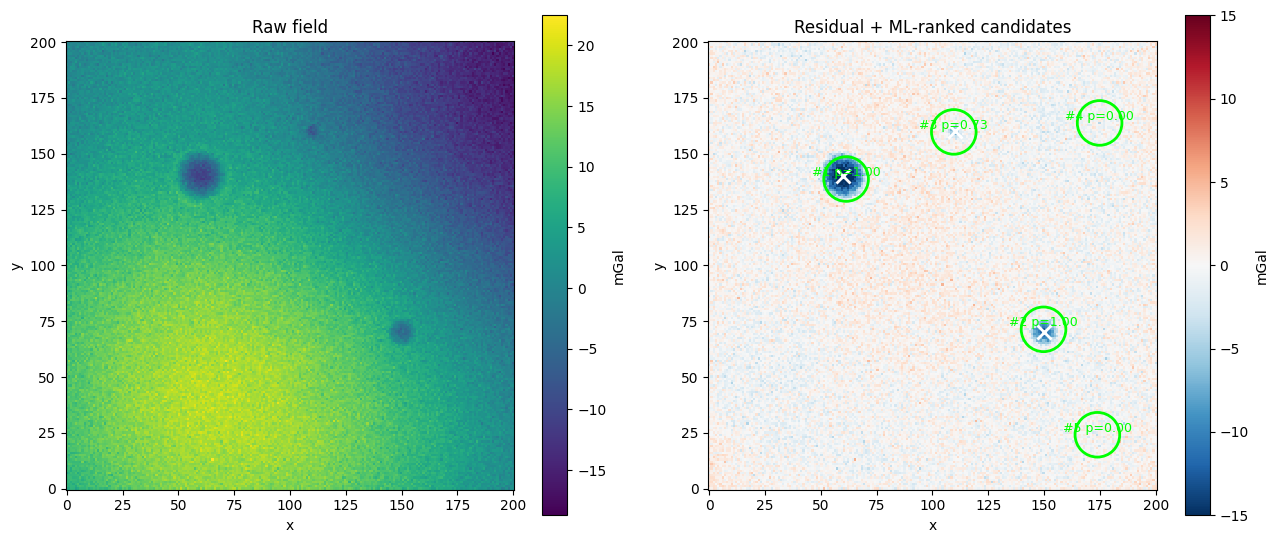

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
im0=axes[0].pcolormesh(x,y,field,shading="auto",cmap="viridis")
axes[0].set_title("Raw field"); fig.colorbar(im0,ax=axes[0],label="mGal")
im1=axes[1].pcolormesh(x,y,res,shading="auto",cmap="RdBu_r",vmin=-15,vmax=15)
axes[1].set_title("Residual + ML-ranked candidates")
for k,(p,sc,cx,cy) in enumerate(rows[:5],1):
    axes[1].add_patch(plt.Circle((cx,cy),10,fill=False,color="lime",lw=2))
    axes[1].annotate(f"#{k} p={p:.2f}",(cx,cy),color="lime",fontsize=9,
                     ha="center",va="bottom")
if truth:
    for cx,cy,r,d in truth: axes[1].plot(cx,cy,"wx",ms=10,mew=2)
fig.colorbar(im1,ax=axes[1],label="mGal")
for ax in axes: ax.set_aspect("equal"); ax.set_xlabel("x"); ax.set_ylabel("y")
plt.tight_layout(); plt.show()

## 10. Next steps

1. **Run locally with `USE_REAL=True`** on an Australian window; verify the XGM2019E
   fetch and array orientation (check `lats`/`lons` ordering — flip if the map is upside
   down).
2. **Calibrate** `order` and thresholds so Wolfe Creek / Gosses Bluff / Spider / Boxhole
   land in your top ranks. If they don't, trend removal is eating the signal.
3. **Multi-scale `r_test`** — loop radii, keep best score per location (real craters span
   orders of magnitude).
4. **Replace the synthetic training cell** with Earth Impact Database positives + your
   detector's unlabeled set; switch to proper PU weighting.
5. **Add magnetic (EMAG2) as feature columns** once gravity-only is working — it's the
   real false-positive filter.
6. **Pretrain on Moon/Mars** crater morphology (clean, no erosion) and transfer, to
   compensate for the tiny Earth positive set.
7. **QGIS pass** on survivors: radial faults, central uplift, stress lineaments. Only
   what survives that is a field/drilling candidate — still not a discovery.